# Random 3-SAT Phase Transition Plot Analysis
Plots showing the phase transition in random 3-SAT, made from the files in ```../results/```.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [23]:
df = pd.read_csv('../results/csv/3sat_parallelized_[25,200]_500_3000.csv')
df.head()

,n,alpha,pr_satisfiable,avg_runtime
0,25,2.000000,1.0,0.000005
1,25,2.133333,1.0,0.000005
2,25,2.266667,1.0,0.000005
3,25,2.400000,1.0,0.000005
4,25,2.533333,1.0,0.000005


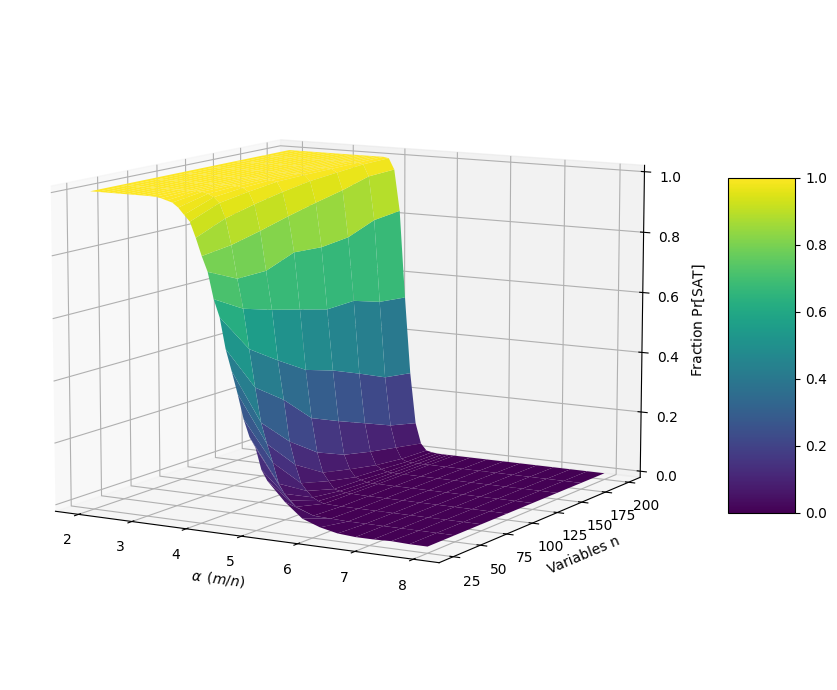

In [31]:
# for n in df['n'].unique():
#     subset = df[df['n'] == n]
#     plt.plot(subset['alpha'], subset['pr_satisfiable'], label=fr"$n={n}$")
# plt.xlabel(r"Clause density $\alpha \,\,\, (m/n)$")
# plt.ylabel(r"Fraction of satisfiable instances $\Pr[\rm SAT]$")
# # plt.title('Phase Transition in Random 3-SAT')
# plt.legend()
# plt.grid()
# plt.show()


pivoted = df.pivot(index='alpha', columns='n', values='pr_satisfiable')

X, Y = np.meshgrid(pivoted.columns, pivoted.index)
Z = pivoted.values

fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(Y, X, Z, cmap='viridis') # Note: Y is alpha, X is n

ax.view_init(elev=10, azim=-60)

ax.set_xlabel(r"$\alpha \,\,\, (m/n)$")
ax.set_ylabel('Variables n')
ax.set_zlabel(r"Fraction $\Pr[\rm SAT]$")
fig.colorbar(surf, shrink=0.5, aspect=5)
plt.tight_layout()
plt.show()

#plt.gca().invert_xaxis()
#cbar = fig.colorbar(surf, shrink=0.5, aspect=7)
#cbar.ax.yaxis.set_major_formatter(FuncFormatter(log_formatter))


# # 1. Load your raw data
# df = pd.read_csv('../results/csv/3sat_parallelized_[50,100]_1000_10000.csv')

# # Create a figure with 2 stacked subplots sharing the X-axis
# fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(7, 9))

# crossing_points = []

# for n in sorted(df['n'].unique()):
#     subset = df[df['n'] == n]
#     x = subset['alpha'].values
#     y_prob = subset['pr_satisfiable'].values
#     y_time = subset['avg_runtime'].values * 1000  # Convert to ms
    
#     # Plot Probability on top (ax1)
#     ax1.plot(x, y_prob, label=fr"$n={n}$")
    
#     # Plot Runtime on bottom (ax2)
#     ax2.plot(x, y_time, label=fr"$n={n}$")
    
#     # Interpolate to find exact alpha where Pr[SAT] = 0.5
#     # np.interp requires x to be increasing, so we reverse the decreasing arrays
#     alpha_cross = np.interp(0.5, y_prob[::-1], x[::-1])
#     if n == 50 or n == 100:
#         crossing_points.append(alpha_cross)

# # --- VISUAL GUIDES ---
# # Draw horizontal line at 0.5 on the probability plot
# ax1.axhline(y=0.5, color='gray', linestyle='--', linewidth=1, alpha=0.7)

# # Shade the region between the n=50 and n=100 crossing points across BOTH plots
# left_bound, right_bound = min(crossing_points), max(crossing_points)
# ax1.axvspan(left_bound, right_bound, color='gray', alpha=0.15)
# ax2.axvspan(left_bound, right_bound, color='gray', alpha=0.15)

# # Optional: Draw faint vertical lines at the edges of the shaded region
# ax1.axvline(x=left_bound, color='gray', linestyle=':', linewidth=1)
# ax1.axvline(x=right_bound, color='gray', linestyle=':', linewidth=1)
# ax2.axvline(x=left_bound, color='gray', linestyle=':', linewidth=1)
# ax2.axvline(x=right_bound, color='gray', linestyle=':', linewidth=1)

# # Formatting Top Plot (Probability)
# ax1.set_ylabel(r"Fraction of satisfiable instances $\Pr[\rm SAT]$")
# ax1.grid(True)
# ax1.legend()

# # Formatting Bottom Plot (Runtime)
# ax2.set_ylabel(r"Average Runtime (ms)")
# ax2.set_xlabel(r"Clause density $\alpha \,\,\, (m/n)$")
# ax2.grid(True)

# plt.tight_layout()
# plt.show()


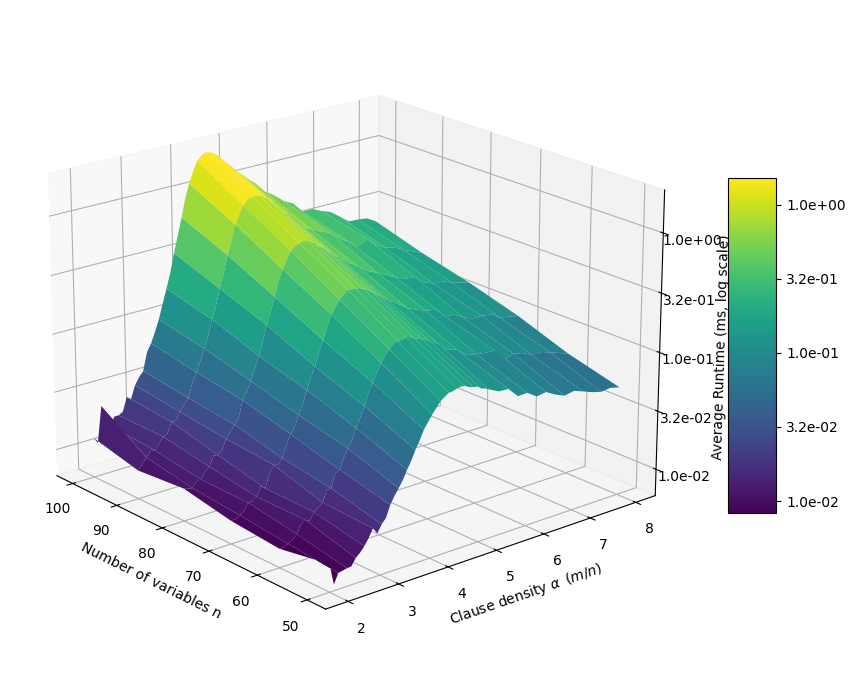

In [5]:
from matplotlib.ticker import FuncFormatter

pivoted = df.pivot(index='alpha', columns='n', values='avg_runtime')

X, Y = np.meshgrid(pivoted.columns, pivoted.index)
Z = pivoted.values
Z = np.log10(pivoted.values * 1000)

fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(X,Y,Z, cmap='viridis') # Note: Y is alpha, X is n

ax.view_init(elev=20, azim=-40)

def log_formatter(x, pos):
    return f"{10**x:.1e}"
ax.zaxis.set_major_formatter(FuncFormatter(log_formatter))

ax.set_xlabel("Number of variables n")
ax.set_ylabel(r"Clause density $\alpha \,\,\, (m/n)$")
ax.set_zlabel("Average Runtime (ms, log scale)")
# ax.set_zlim(np.log10(0.0001), np.log10(0.0020))
plt.gca().invert_xaxis()
# plt.gca().set_zscale('log')
# fig.colorbar(surf, shrink=0.5, aspect=5)
cbar = fig.colorbar(surf, shrink=0.5, aspect=7)
cbar.ax.yaxis.set_major_formatter(FuncFormatter(log_formatter))
plt.tight_layout()
plt.show()

# df['avg_runtime_ms'] = df['avg_runtime'] * 1000

# for n in df['n'].unique():
#     subset = df[df['n'] == n]
#     plt.plot(subset['alpha'], subset['avg_runtime_ms'], label=fr"$n={n}$")
# plt.yscale('log')
# plt.xlabel(r"Clause density $\alpha \,\,\, (m/n)$")
# plt.ylabel("Average Runtime (ms, log scale)")
# # plt.title('Solver Runtime vs Clause Density')
# plt.legend()
# plt.grid()
# plt.show()

In [2]:
df = pd.read_csv('../results/ite_transition_10_25.csv')
df.head()

,n,alpha,pr_satisfiable,avg_runtime
0,10,1.000000,0.9999,0.000004
1,10,1.230769,0.9994,0.000004
2,10,1.461538,0.9997,0.000004
3,10,1.692308,0.9998,0.000005
4,10,1.923077,1.0000,0.000005


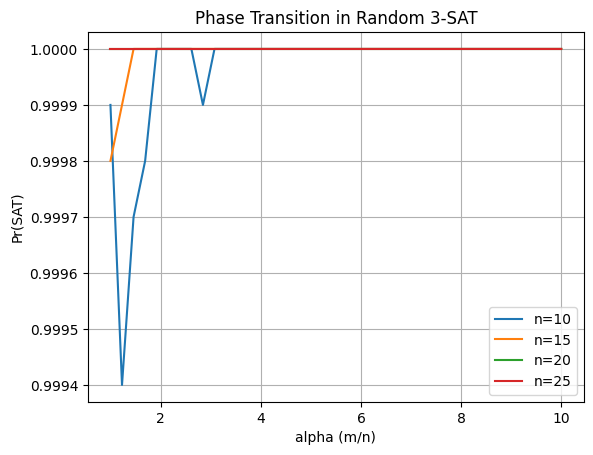

In [3]:
for n in df['n'].unique():
    subset = df[df['n'] == n]
    plt.plot(subset['alpha'], subset['pr_satisfiable'], label=f'n={n}')
plt.xlabel('alpha (m/n)')
plt.ylabel('Pr(SAT)')
plt.title('Phase Transition in Random 3-SAT')
plt.legend()
plt.grid()
plt.show()

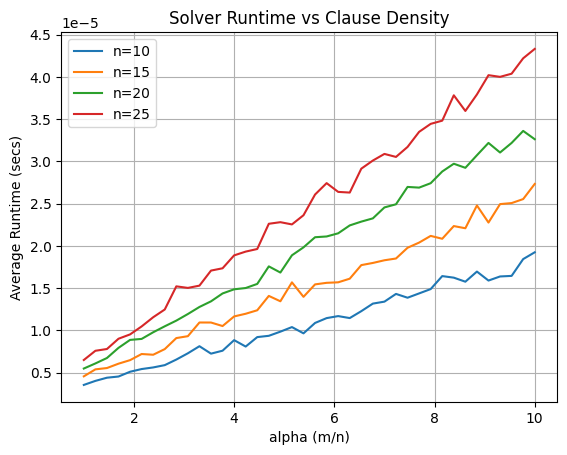

In [4]:
for n in df['n'].unique():
    subset = df[df['n'] == n]
    plt.plot(subset['alpha'], subset['avg_runtime'], label=f'n={n}')
# plt.yscale('log')
plt.xlabel('alpha (m/n)')
plt.ylabel('Average Runtime (secs)')
plt.title('Solver Runtime vs Clause Density')
plt.legend()
plt.grid()
plt.show()

In [2]:
df = pd.read_csv('../results/3sat_parallelized_[25,100]_500_10000.csv')
df.head()

,n,alpha,pr_satisfiable,avg_runtime
0,25,3.000000,1.000,0.000007
1,25,3.057143,1.000,0.000008
2,25,3.114286,1.000,0.000009
3,25,3.171429,0.998,0.000009
4,25,3.228571,1.000,0.000009


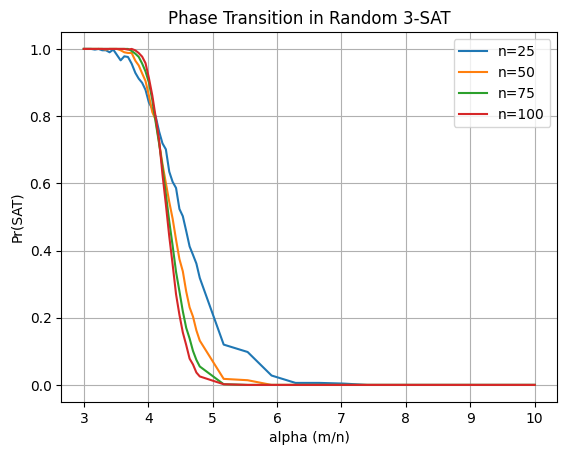

In [3]:
for n in df['n'].unique():
    subset = df[df['n'] == n]
    plt.plot(subset['alpha'], subset['pr_satisfiable'], label=f'n={n}')
plt.xlabel('alpha (m/n)')
plt.ylabel('Pr(SAT)')
plt.title('Phase Transition in Random 3-SAT')
plt.legend()
plt.grid()
plt.show()

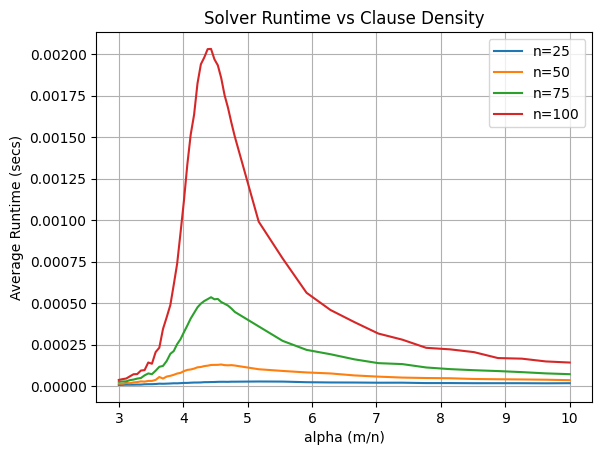

In [4]:
for n in df['n'].unique():
    subset = df[df['n'] == n]
    plt.plot(subset['alpha'], subset['avg_runtime'], label=f'n={n}')
# plt.yscale('log')
plt.xlabel('alpha (m/n)')
plt.ylabel('Average Runtime (secs)')
plt.title('Solver Runtime vs Clause Density')
plt.legend()
plt.grid()
plt.show()